# Module 09, Part 3: Deep Q-networks, replay buffers and target networks

This notebook is the runnable companion to Part 3 of the Module 09 learning content. It checks, with code:

1. That a DQN with a replay buffer and a target network learns to balance a pole, and how much the result varies between seeds.
2. What happens when the target network is removed: we log the network's own estimate of the value of a state and compare it with the largest value it could possibly have.
3. What happens when the replay buffer is removed, in two ways that are easy to confuse: updating on the most recent 64 transitions, and updating on the single latest transition.
4. What each of these costs in interaction and in compute.

**Task.** CartPole, written in plain numpy so nothing needs to be downloaded: push a cart left or right to keep a pole upright. The reward is +1 for every step the pole stays up and an episode stops after 200 steps, so 200 is the best possible return. A random policy scores about 22. The discount factor is 0.99, so the largest possible value of any state is $1/(1-0.99) = 100$.
Every setting uses the same network (two hidden layers of 64 units), the same learning rate, and 30,000 environment steps, with three seeds. Learning curves show the mean return of the episodes that ended in the last 2,000 steps.

In [1]:
import copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from multiprocessing import Pool
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import math
import numpy as np


class CartPole:
    """State: cart position, cart velocity, pole angle, pole angular velocity.
    Actions: 0 pushes the cart left, 1 pushes it right. Reward is +1 for every step the pole stays up.
    An episode ends when the pole tilts past 12 degrees, the cart leaves the track, or max_steps is reached."""
    n_actions = 2
    obs_dim = 4

    def __init__(self, seed=0, max_steps=200):
        self.rng = np.random.default_rng(seed)
        self.max_steps = max_steps
        self.g, self.mc, self.mp, self.l, self.force, self.tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
        self.theta_lim = 12 * 2 * math.pi / 360
        self.x_lim = 2.4

    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, size=4)
        self.t = 0
        return self.s.astype(np.float32)

    def step(self, a):
        x, xd, th, thd = self.s
        f = self.force if a == 1 else -self.force
        ct, st = math.cos(th), math.sin(th)
        tm = self.mc + self.mp
        pml = self.mp * self.l
        tmp = (f + pml * thd ** 2 * st) / tm
        tha = (self.g * st - ct * tmp) / (self.l * (4.0 / 3.0 - self.mp * ct ** 2 / tm))
        xa = tmp - pml * tha * ct / tm
        x, xd = x + self.tau * xd, xd + self.tau * xa
        th, thd = th + self.tau * thd, thd + self.tau * tha
        self.s = np.array([x, xd, th, thd])
        self.t += 1
        terminated = bool(abs(x) > self.x_lim or abs(th) > self.theta_lim)
        truncated = self.t >= self.max_steps
        return self.s.astype(np.float32), 1.0, terminated, truncated

In [3]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from cartpole import CartPole


class QNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, n_actions))

    def forward(self, x):
        return self.net(x)


class Replay:
    """A ring buffer of transitions. With capacity equal to the batch size, a 'batch' is just the latest
    transitions in the order they happened, which is what learning without replay means."""
    def __init__(self, capacity, obs_dim=4):
        self.cap, self.n, self.i = capacity, 0, 0
        self.s = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64)
        self.r = np.zeros(capacity, np.float32)
        self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.d = np.zeros(capacity, np.float32)

    def add(self, s, a, r, s2, d):
        self.s[self.i], self.a[self.i], self.r[self.i], self.s2[self.i], self.d[self.i] = s, a, r, s2, d
        self.i = (self.i + 1) % self.cap
        self.n = min(self.n + 1, self.cap)

    def sample(self, batch, rng):
        idx = rng.integers(0, self.n, size=batch)
        return [torch.as_tensor(x[idx]) for x in (self.s, self.a, self.r, self.s2, self.d)]


def train_dqn(seed=0, steps=20000, replay=True, target=True, gamma=0.99, lr=1e-3, batch=64,
              buffer=20000, warmup=500, target_every=250, eps_start=1.0, eps_end=0.05, eps_decay=8000,
              max_steps=200, log_every=None):
    """Returns the list of (env step at the end of the episode, episode return).
    replay=False: the buffer holds only the latest `batch` transitions, so every update uses consecutive,
        strongly correlated experience that is then thrown away.
    target=False: the bootstrap target is computed with the network that is being trained."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    env = CartPole(seed, max_steps)
    q = QNet()
    q_tgt = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buf = Replay(buffer if replay else batch)
    warm = warmup if replay else batch
    s = env.reset()
    ep_ret, episodes, q_log = 0.0, [], []
    for t in range(1, steps + 1):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / eps_decay)
        if rng.random() < eps:
            a = int(rng.integers(2))
        else:
            with torch.no_grad():
                a = int(q(torch.as_tensor(s)[None]).argmax())
        s2, r, term, trunc = env.step(a)
        buf.add(s, a, r, s2, float(term))      # time-limit truncation is not a true terminal state
        ep_ret += r
        s = s2
        if term or trunc:
            episodes.append((t, ep_ret)); ep_ret = 0.0; s = env.reset()
        if t >= warm:
            bs, ba, br, bs2, bd = buf.sample(batch, rng) if replay else \
                [torch.as_tensor(x[:batch]) for x in (buf.s, buf.a, buf.r, buf.s2, buf.d)]
            if not replay and batch > 1:    # order the ring buffer so the batch really is the latest transitions
                order = [(buf.i + k) % buf.cap for k in range(buf.cap)]
                bs, ba, br, bs2, bd = [torch.as_tensor(x[order]) for x in (buf.s, buf.a, buf.r, buf.s2, buf.d)]
            with torch.no_grad():
                net = q_tgt if target else q
                y = br + gamma * (1 - bd) * net(bs2).max(1).values
            pred = q(bs).gather(1, ba[:, None])[:, 0]
            loss = F.smooth_l1_loss(pred, y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), 10.0)
            opt.step()
            if target and t % target_every == 0:
                q_tgt.load_state_dict(q.state_dict())
            if log_every and t % log_every == 0:
                with torch.no_grad():
                    q_log.append((t, float(q(bs).max(1).values.mean())))
    return (episodes, q_log) if log_every else episodes


def smooth_curve(episodes, steps, grid=500, window=2000):
    """Mean return of the episodes that ended in the last `window` steps, evaluated every `grid` steps."""
    ts = np.array([e[0] for e in episodes]); rs = np.array([e[1] for e in episodes])
    out = []
    for g in range(grid, steps + 1, grid):
        m = (ts > g - window) & (ts <= g)
        out.append(rs[m].mean() if m.any() else np.nan)
    return np.array(out)

## 1. The environment

Before training anything we check the environment itself: a random policy, and a hand-written feedback rule that pushes the cart towards the side the pole is falling to.

In [4]:
def episode_length(policy, seed):
    env = CartPole(seed); s = env.reset(); n = 0
    while True:
        s, _, term, trunc = env.step(policy(s, n)); n += 1
        if term or trunc: return n
rng = np.random.default_rng(0)
print("random policy, mean episode length over 200 episodes:", np.mean([episode_length(lambda s, n: int(rng.integers(2)), k) for k in range(200)]))
print("feedback rule (push towards the lean):", [episode_length(lambda s, n: int(s[2] + 0.5 * s[3] > 0), k) for k in range(5)])

random policy, mean episode length over 200 episodes: 22.69
feedback rule (push towards the lean): [200, 200, 200, 200, 200]


## 2. The target, and the five settings

The DQN update moves $Q(s, a)$ towards the target $y = r + \gamma \max_{a'} Q_{\text{target}}(s', a')$, using the Huber loss on a mini-batch. Two details do most of the work.

- **The replay buffer** stores the last 20,000 transitions and each update draws 64 of them at random. This reuses every experience many times and breaks up the strong correlation between consecutive steps.
- **The target network** is a copy of the Q network that is refreshed every 250 steps, so the target $y$ does not change after every gradient step.

We train five settings. **Full** has both. **Window of 64** removes the buffer but still trains on the latest 64 consecutive transitions at each step. **Online** removes the buffer and trains on the latest single transition. **Replay, batch 1** keeps the buffer but trains on one random transition per step, so that it differs from online in one thing only. **No target** has the buffer and trains towards a target computed by the network being trained.

In [5]:
STEPS = 30000
configs = {
    "full":            dict(),
    "window of 64":    dict(replay=False),
    "online (batch 1)": dict(replay=False, batch=1),
    "replay, batch 1": dict(batch=1),
    "no target":       dict(target=False),
}
def run(job):
    torch.set_num_threads(1)
    name, seed = job
    t0 = time.time()
    ep, qlog = train_dqn(seed, steps=STEPS, log_every=500, **configs[name])
    return name, seed, smooth_curve(ep, STEPS), qlog, time.time() - t0
jobs = [(n, s) for n in configs for s in range(3)]
with Pool(2) as pool:
    results = pool.map(run, jobs)
curves = {n: np.array([r[2] for r in results if r[0] == n]) for n in configs}
qlogs = {n: np.array([[x[1] for x in r[3]] for r in results if r[0] == n]) for n in configs}
secs = {n: np.mean([r[4] for r in results if r[0] == n]) for n in configs}

## 3. Learning curves

The table reports, for each seed, the mean return over the last 5,000 steps (the last ten points of each curve), and the mean and spread over the three seeds.

setting                 per seed (last 5,000 steps)    mean    std
full                               [ 78. 144. 121.]   114.1   27.2
window of 64                       [135. 139. 139.]   137.4    2.1
online (batch 1)                      [20. 19. 18.]    19.2    0.8
replay, batch 1                       [60. 66. 82.]    69.3    9.5
no target                             [10.  9. 10.]     9.6    0.1


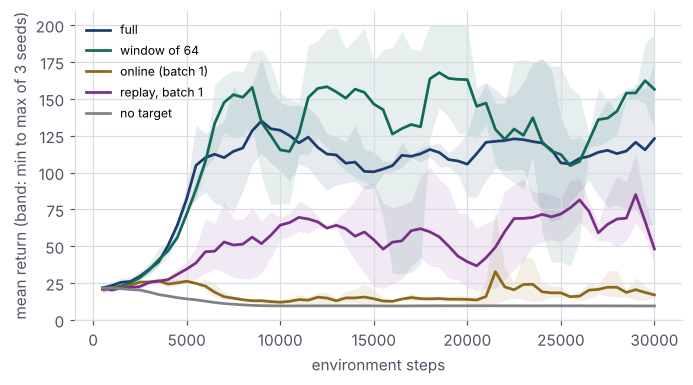

In [6]:
print(f"{'setting':18s} {'per seed (last 5,000 steps)':>32s} {'mean':>7s} {'std':>6s}")
for n in configs:
    last = np.nanmean(curves[n][:, -10:], axis=1)
    print(f"{n:18s} {str(np.round(last, 0)):>32s} {last.mean():7.1f} {last.std():6.1f}")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
xs = np.arange(500, STEPS + 1, 500)
cols = {"full": NAVY, "window of 64": GREEN, "online (batch 1)": AMBER, "replay, batch 1": KEY, "no target": MUTED}
for n in configs:
    ax.plot(xs, np.nanmean(curves[n], 0), color=cols[n], label=n, lw=1.8)
    ax.fill_between(xs, np.nanmin(curves[n], 0), np.nanmax(curves[n], 0), color=cols[n], alpha=0.10, lw=0)
ax.set_xlabel("environment steps"); ax.set_ylabel("mean return (band: min to max of 3 seeds)"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

Four things stand out. The full agent learns, but its seeds disagree widely (78, 144 and 121), so three seeds are barely enough to rank anything close. Removing the target network is catastrophic: the return falls to about 10, the number you get by pushing the same way every step. Removing the buffer is not one change but two, and the table separates them.
Training on the latest 64 consecutive transitions did at least as well as the full agent here (137 against 114, with the full agent's spread larger than the gap), while training on the single latest transition failed (19). Part of what a buffer provides is reuse of data: each transition contributes to many updates, and the window gives that reuse too, 64 times over.
The buffer matters in its own right as well: with one transition per update, the agent that samples it from the buffer reached 69 and the agent that uses the latest one reached 19, so at equal batch size, random replay is the better of the two. That the window matched the buffer should not be read as "replay does not matter": at larger scale, with images and long episodes, consecutive frames are far more alike than they are here.

## 4. The value estimate with and without a target network

For this task no state can be worth more than 100. We logged the mean of the largest Q value on each training batch every 500 steps. With a target network the estimates rise towards the true scale, between 60 and 110 after 30,000 steps. Without one, they have nothing to hold on to.

In [7]:
print("mean of max Q on the training batch (the true value cannot exceed 100)")
print(f"{'setting':18s} {'5,000 steps':>14s} {'15,000 steps':>14s} {'30,000 steps':>14s}")
for n in configs:
    q = qlogs[n].mean(0)
    print(f"{n:18s} {q[9]:14.1f} {q[29]:14.1f} {q[59]:14.1f}")
print()
print("no target, per seed, at 30,000 steps:", np.round(qlogs["no target"][:, -1], 0))

mean of max Q on the training batch (the true value cannot exceed 100)
setting               5,000 steps   15,000 steps   30,000 steps
full                         17.4           47.0           67.6
window of 64                 18.7           45.7           64.2
online (batch 1)             19.1           54.9          105.5
replay, batch 1              17.4           47.1           80.7
no target                366451.8     18642472.3    199959578.7

no target, per seed, at 30,000 steps: [1.66966944e+08 2.20578640e+08 2.12333152e+08]


Without the target network, the value estimate is orders of magnitude beyond the bound (about 2e8 against a limit of 100): the network is chasing a target that it moves with every step, and each overestimate feeds the next. With the target network the estimates are of the right size, though not always below the bound: the full agent ends at about 68, and the online agent, the worst learner, ends at 105, slightly above it.
Overestimation is a property of the max in the target and the noise in the network, and the target network contains it rather than removing it. The agent that diverged is not "a bad run": all three seeds did the same.

## 5. What each setting costs

All five settings use the same number of environment steps. They differ in how much computation each step needs and in how reliably they work.

In [8]:
print(f"{'setting':18s} {'seconds per run':>16s} {'gradient updates':>18s} {'transitions used per update':>28s}")
for n, kw in configs.items():
    batch = kw.get("batch", 64); warm = 500 if kw.get("replay", True) else batch
    updates = STEPS - warm + 1
    print(f"{n:18s} {secs[n]:16.0f} {updates:18d} {batch:28d}")

setting             seconds per run   gradient updates  transitions used per update
full                             44              29501                           64
window of 64                     33              29937                           64
online (batch 1)                 28              30000                            1
replay, batch 1                  29              29501                            1
no target                        31              29501                           64


The cost of one run is small here and that is the point of choosing CartPole: three seeds of five settings finish in minutes. The same experiment on a task with images would take days, which is why RL papers with fewer than five seeds, or with only the best seed shown, deserve suspicion.

**Try it.** Change `target_every` to 10 and to 5,000 and see how the learning curve and the largest Q value respond. Then train the full agent for 100,000 steps: does it settle at 200, or does the return fall back after reaching it?